# Performance profiling for anemoi

**Make your model faster. Make your model fit in GPU memory.**

In this notebook, you measure the speed and the memory use of an anemoi model.
You use two tools:

1. The **memory snapshot**. It shows how much GPU memory the model uses at each moment of a training step.
2. The **profiler trace**. It shows what the CPU and the GPU do at each moment, and how long each operation takes.

Then you change two model settings and you measure the effect:

* `num_chunks`
* `gradient_checkpointing`

At the end, there is a thought experiment about **model sharding** (one model on more than one GPU).

### What you need

* One GPU.
* Approximately 60 to 90 minutes.
* A web browser on your laptop, to open the memory snapshot and the trace.

You do not need to know about GPU programming. We explain each new word when we use it.

### Structure

| Part | Subject | Time |
|---|---|---|
| 0 | Set up and important words | 10 min |
| 1 | Warm-up: profile a very small PyTorch model | 15 min |
| 2 | Profile an anemoi model | 20 min |
| 3 | Experiments: gradient checkpointing and chunking | 20 min |
| 4 | Your own experiments | 15 min |
| 5 | Thought experiment: model sharding | 10 min |

This notebook is based on the [anemoi performance optimisation guide](https://anemoi.readthedocs.io/projects/training/en/latest/user-guide/performance-optimisation.html).

---
## Part 0: Set up and important words

### 0.1 Important words

| Word | Meaning |
|---|---|
| **GPU memory** | The memory on the GPU. All the data that the GPU uses must be in this memory. It is small (for example 40 GB to 96 GB). When it is full, you get the error `CUDA out of memory` (OOM). |
| **Forward pass** | The model calculates a forecast from the input. |
| **Backward pass** | The model calculates the gradients of the loss. The optimiser uses the gradients to update the weights. |
| **Training step** (iteration) | One forward pass, one backward pass and one optimiser update. |
| **Activations** | The intermediate results of the forward pass. The backward pass needs them. Usually, they use most of the GPU memory. |
| **Throughput** | The number of training steps for each second (it/s). Higher is better. |
| **Kernel** | One small program that the GPU runs, for example one matrix multiplication. |
| **Peak memory** | The maximum GPU memory that the model uses at one moment. If the peak is more than the GPU memory, the run stops. |

### 0.2 The parts of an anemoi model

An anemoi model has three parts:

```
  data grid (for example O96, 40 320 points)
        │
        ▼
  ┌───────────┐
  │  ENCODER  │   maps the data grid to a coarser "latent" grid   (many edges → much memory)
  └───────────┘
        │
        ▼
  ┌───────────┐
  │ PROCESSOR │   16 layers on the latent grid                    (most of the calculation)
  └───────────┘
        │
        ▼
  ┌───────────┐
  │  DECODER  │   maps the latent grid back to the data grid      (many edges → much memory)
  └───────────┘
```

The encoder and the decoder are also called the **mappers**. They connect many grid points with many edges, so they make large activations.

### 0.3 Make sure that you have a GPU

Run the cell below. It shows the name of your GPU and its total memory.

In [1]:
# run once at the start to ensure you have torch
!pip install torch

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import torch

assert torch.cuda.is_available(), "No GPU found. Make sure that you start this notebook on a GPU node."

gpu = torch.cuda.get_device_properties(0)
print(f"GPU name:     {gpu.name}")
print(f"GPU memory:   {gpu.total_memory / 1e9:.1f} GB")
print(f"PyTorch:      {torch.__version__}")

GPU name:     NVIDIA A100-SXM4-40GB
GPU memory:   42.6 GB
PyTorch:      2.10.0+cu128


### 0.4 Import the helper functions

The file `perf_helpers.py` is in the same folder as this notebook.
It has functions that start anemoi runs and read the results.
You can read the file, but it is not necessary for the exercises.

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

import perf_helpers as ph

# The O96 dataset is set in perf_profiling.yaml. We use this N320 dataset in Part 3.3.
N320_DATASET = "/home/mlx/ai-ml/datasets/aifs-ea-an-oper-0001-mars-n320-1979-2023-6h-v8.zarr"

---
## Part 1: Warm-up with a very small PyTorch model

Before we use anemoi, we use a very small model. Each cell runs in a few seconds.
This part shows the most important ideas.

The model is a simple two-layer network (an "MLP"). We apply it to 200 000 points.
This is approximately the number of edges in a small anemoi mapper.

In [17]:
import time

import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

device = "cuda"
torch.manual_seed(0)

N_POINTS, N_IN, N_HIDDEN = 200_000, 256, 2048

x = torch.randn(N_POINTS, N_IN, device=device, requires_grad=True)
W1 = torch.randn(N_IN, N_HIDDEN, device=device, requires_grad=True)
W2 = torch.randn(N_HIDDEN, N_IN, device=device, requires_grad=True)


def mlp(inp):
    # The intermediate result has the shape (points, N_HIDDEN). It is large.
    return F.gelu(inp @ W1) @ W2


print(f"Size of the input:               {x.numel() * 4 / 1e9:.2f} GB")
print(f"Size of one intermediate result: {N_POINTS * N_HIDDEN * 4 / 1e9:.2f} GB")

Size of the input:               0.20 GB
Size of one intermediate result: 1.64 GB


### 1.1 How to measure time on a GPU correctly

The CPU sends work to the GPU, and then it continues immediately. It does not wait for the GPU.
Thus, if you measure time on the CPU only, the result can be wrong.

Run the cell below. It measures the same calculation two times:

* first, without `torch.cuda.synchronize()`
* then, with `torch.cuda.synchronize()`. This function makes the CPU wait until the GPU has completed all its work.

In [23]:
def timed(fn, sync):
    if sync:
        torch.cuda.synchronize()
    start = time.perf_counter()
    fn()
    if sync:
        torch.cuda.synchronize()
    return (time.perf_counter() - start) * 1000


with torch.no_grad():
    mlp(x)  # The first call is slower (warm-up). We do not measure it.
    print(f"Without synchronize: {timed(lambda: mlp(x), sync=False):6.2f} ms   <-- not correct")
    print(f"With synchronize:    {timed(lambda: mlp(x), sync=True):6.2f} ms   <-- correct")

Without synchronize:   0.06 ms   <-- not correct
With synchronize:     30.78 ms   <-- correct


> **Remember:** The GPU works *asynchronously*. Always synchronize before you read a timer.
> The anemoi profiler does this for you.
>
> **Also remember:** The first steps are always slower (warm-up). Do not measure them. This is why the profiler has a `warmup` setting.

### 1.2 Measure the peak memory of one training step

The function below does one training step on a part of the points, and measures:

* the **peak memory** with `torch.cuda.max_memory_allocated()`
* the **time**

It has two settings. We explain them in the next sections:

* `chunks`: divide the points into this number of parts, and calculate one part after the other.
* `ckpt`: use gradient checkpointing.

In [24]:
def train_step(chunks=1, ckpt=False):
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    memory_before = torch.cuda.memory_allocated()
    start = time.perf_counter()

    outputs = []
    for x_chunk in x.chunk(chunks):
        if ckpt:
            outputs.append(checkpoint(mlp, x_chunk, use_reentrant=False))
        else:
            outputs.append(mlp(x_chunk))
    loss = torch.cat(outputs).square().mean()
    loss.backward()

    torch.cuda.synchronize()
    elapsed_ms = (time.perf_counter() - start) * 1000
    peak_gb = (torch.cuda.max_memory_allocated() - memory_before) / 1e9
    x.grad = W1.grad = W2.grad = None
    return peak_gb, elapsed_ms


train_step()  # warm-up
peak, ms = train_step()
print(f"chunks=1, no checkpointing:  peak memory {peak:.2f} GB, time {ms:.1f} ms")

chunks=1, no checkpointing:  peak memory 5.33 GB, time 99.7 ms


### 1.3 Record a memory snapshot

The peak value is useful, but it does not tell you *where* the memory goes.
A **memory snapshot** records each memory allocation and each memory release on the GPU.

Use these PyTorch functions:

* `torch.cuda.memory._record_memory_history()` starts the recording.
* `torch.cuda.memory._dump_snapshot("file.pickle")` writes the recording to a file.

anemoi uses the same functions (the `MemorySnapshotRecorder`). Run the cell below.

In [22]:
torch.cuda.memory._record_memory_history(max_entries=100_000)

for _ in range(3):  # three training steps
    train_step(chunks=1, ckpt=False)

torch.cuda.memory._dump_snapshot("toy_snapshot.pickle")
torch.cuda.memory._record_memory_history(enabled=None)  # stop the recording
print("Saved toy_snapshot.pickle")

Saved toy_snapshot.pickle


The helper function `ph.memory_timeline` reads the snapshot and calculates the allocated memory over time.

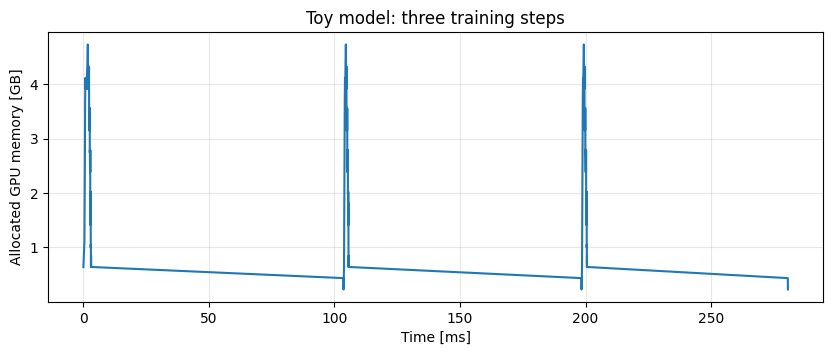

In [20]:
import pickle

with open("toy_snapshot.pickle", "rb") as f:
    toy_snapshot = pickle.load(f)

t, mem = ph.memory_timeline(toy_snapshot)
plt.figure(figsize=(10, 3.5))
plt.plot(t * 1000, mem)
plt.xlabel("Time [ms]")
plt.ylabel("Allocated GPU memory [GB]")
plt.title("Toy model: three training steps")
plt.grid(alpha=0.3)
plt.show()

**Question:** You can see three "mountains" in the plot, one for each training step.

* In which part of the step does the memory increase? (forward pass or backward pass?)
* In which part of the step does the memory decrease?

<details>
<summary>Answer</summary>

The memory increases during the forward pass, because PyTorch keeps the activations for the backward pass.
The memory decreases during the backward pass, because PyTorch releases each activation after it has used it.
The peak is at the end of the forward pass and the start of the backward pass.
</details>

#### Open the snapshot in the interactive viewer

1. In the JupyterLab file browser (on the left), right-click `toy_snapshot.pickle`. Select **Download**.
2. On your laptop, open [https://pytorch.org/memory_viz](https://pytorch.org/memory_viz).
3. Drag the file into the web page.
4. Move the mouse over a coloured block. The viewer shows the size of the block and the Python code that allocated it (the "stack trace").

> The file stays on your laptop. The viewer does not send the file to a server.

### 1.4 Chunking

The large intermediate result has the shape `(points, 2048)`.
If we calculate the points in 8 parts (**chunks**), one part after the other, each intermediate result is 8 times smaller.

### 1.5 Gradient checkpointing

**Gradient checkpointing** does not keep the activations for the backward pass.
Instead, it calculates them again during the backward pass.
This uses less memory, but more calculation.

### 1.6 Compare the four combinations

Before you run the cell below, **make a prediction**:
which combination uses the least memory? Which combination is the slowest?

In [25]:
import pandas as pd

rows = []
for chunks, ckpt in [(1, False), (8, False), (1, True), (8, True)]:
    train_step(chunks, ckpt)  # warm-up
    peak, ms = train_step(chunks, ckpt)
    rows.append({"chunks": chunks, "checkpointing": ckpt, "peak memory [GB]": round(peak, 2), "time [ms]": round(ms, 1)})

pd.DataFrame(rows)

,chunks,checkpointing,peak memory [GB],time [ms]
0,1,False,5.33,88.9
1,8,False,4.51,91.5
2,1,True,5.33,93.8
3,8,True,1.23,98.4


**Questions:**

1. Chunking alone: did the memory decrease much? Why not?
2. Checkpointing alone: did the memory decrease? Why not?
3. Chunking and checkpointing together: what is the result?

<details>
<summary>Answer</summary>

1. Only a little. Without checkpointing, PyTorch must keep the activations of **all** chunks for the backward pass. Thus the total is almost the same.
2. No. With one chunk, the backward pass calculates the large intermediate result again. Thus the peak is the same.
3. A large decrease. Each chunk is checkpointed, thus PyTorch keeps only the small output of each chunk. During the backward pass, it calculates one chunk again at a time. The peak is approximately one chunk.

The cost is more time, because the forward pass of the checkpointed part runs two times.

**anemoi does the same thing.** In the mappers, it checkpoints each chunk.
This is why the two settings `num_chunks` and `gradient_checkpointing` work together.
</details>

### 1.7 Record a profiler trace

The memory snapshot shows the memory. The **profiler trace** shows the time.
It records each operation on the CPU and each kernel on the GPU.

Run the cell below. It records three training steps and writes the file `toy_trace.json`.

In [26]:
from torch.profiler import ProfilerActivity, profile, record_function

with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA], record_shapes=True) as prof:
    for _ in range(3):
        with record_function("my_training_step"):  # a label that you can see in the trace
            train_step(chunks=8, ckpt=True)

prof.export_chrome_trace("toy_trace.json")
print(prof.key_averages().table(sort_by="cuda_time_total", row_limit=8))

-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                               aten::mm         1.61%       5.446ms         2.16%       7.302ms      38.030us     255.742ms        89.76%     255.742ms       1.332ms           192  
       autograd::engine::evaluate_function: MmBackward0         0.30%       1.003ms         3.84%      13.010ms     271.035us       0.000us         0.00%     210.429ms       4.384ms            48  
         

The table shows the operations that used the most GPU time. `aten::mm` is a matrix multiplication.

#### Open the trace in Perfetto

1. Download `toy_trace.json` (right-click, **Download**).
2. Open [https://ui.perfetto.dev](https://ui.perfetto.dev) and click **Open trace file**.
3. Use the keys **W** and **S** to zoom in and out. Use **A** and **D** to move left and right.

The trace has two important areas:

* the **CPU threads** (at the top): the Python code and the operations that the CPU sends to the GPU.
* the **GPU stream** (at the bottom, for example "stream 7"): the kernels that the GPU runs.

**Exercise:** Find the three `my_training_step` blocks. In one step, find the 8 chunks of the forward pass.
Then find the backward pass. Can you see that the backward pass calculates the forward pass of each chunk again?

> **Tip:** If there are gaps in the GPU stream, the GPU is waiting. Usually, this means that the CPU is too slow,
> or that the GPU waits for data. A good training run has very few gaps on the GPU.

### 1.8 Release the GPU memory

The anemoi runs in the next part use the same GPU. Run the cell below to release the memory of the toy model.

In [27]:
del x, W1, W2, toy_snapshot
torch.cuda.empty_cache()
print(f"Memory still allocated by this notebook: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Memory still allocated by this notebook: 0.02 GB


---
## Part 2: Profile an anemoi model

### 2.1 The configuration

The file `perf_profiling.yaml` is the configuration for all the runs in this notebook.
It is a normal anemoi training configuration, with these changes:

* It trains on **20 batches** only, with a batch size of 1. A run takes approximately 1 to 2 minutes.
* It uses the ERA5 dataset on the O96 grid (approximately 1 degree) and a GraphTransformer model.
* It switches on the **benchmark profiler** (`diagnostics.benchmark_profiler`).

Run the cell below to see the configuration.

In [28]:
print(open("perf_profiling.yaml").read())

defaults:
  - data: zarr
  - dataloader: native_grid
  - diagnostics: evaluation
  - system: example
  - graph: multi_scale
  - model: graphtransformer
  - task: forecaster
  - training: single
  - _self_

config_validation: True

system:
  hardware:
    num_gpus_per_node: 1
    num_nodes: 1
    num_gpus_per_model: 1
  input:
    dataset: /home/mlx/ai-ml/datasets/aifs-ea-an-oper-0001-mars-o96-1979-2023-6h-v8.zarr
    graph: ./graphs/o96_multiscale_graph.pt
  output:
    root: ./outputs/default

graph:
  overwrite: False

dataloader:
  num_workers:
    training: 2
    validation: 2
  batch_size:
    training: 1
    validation: 1
  limit_batches:
    training: 20
    validation: 2
  training:
    datasets:
      data:
        start: 2020
        end: 2020

model:
  compile: []

training:
  max_epochs: 1
  num_sanity_val_steps: 0

diagnostics:
  callbacks: []
  plot:
    callbacks: []
  enable_checkpointing: False
  print_memory_summary: False
  log:
    mlflow:
      enabled: False
     

Look at the `benchmark_profiler` section:

| Setting | What it does |
|---|---|
| `memory.enabled` | Records a **profiler trace** (a `*.pt.trace.json` file) for `steps` steps, after `warmup` steps. |
| `snapshot.enabled` | Records a **memory snapshot** (`memory_snapshot.pickle`) for `steps` steps, after `warmup` steps. |
| `time.enabled` | Writes a report of the time for each part of the training loop. |
| `speed.enabled` | Writes a report of the throughput. |

> **Note:** We record only 2 steps. A trace of many steps is a very large file, and the web viewers become slow.

To start a profiling run from a terminal, you use the command `anemoi-training profile` (not `anemoi-training train`):

```bash
anemoi-training profile --config-name=perf_profiling
```

In this notebook, the helper function `ph.run_experiment()` runs this command for you.
You give it a name and a list of configuration changes ("overrides").

### 2.2 Run the baseline

The **baseline** uses the default settings of anemoi:

* `num_chunks: 4` in the encoder, the processor and the decoder
* `gradient_checkpointing: True` in the encoder, the processor and the decoder

Run the cell below. It takes approximately 1 to 2 minutes. The first run can take longer, because it creates the graph.
While you wait, read the log file `outputs/baseline/run.log`.

In [30]:
experiments = {}
experiments["baseline"] = ph.run_experiment("baseline", force=True)
experiments["baseline"]

Command: anemoi-training profile --config-name=perf_profiling system.output.root=outputs/baseline
Log file: outputs/baseline/run.log
Finished in 58 s with exit code 0.


PosixPath('outputs/baseline/profiler/bb3cc54e-6e25-40b6-88bb-c81d17df4c01')

### 2.3 The output files

The run writes all the profiler files into one folder. Run the cell below to see the files.

In [31]:
for f in sorted(experiments["baseline"].iterdir()):
    print(f"{f.stat().st_size / 1e6:10.1f} MB   {f.name}")

     121.4 MB   ac6-305.bullx_3267928.None.1793092405474388984.pt.trace.json
      32.0 MB   ac6-305.bullx_3267928.None.1793092423191065630.pt.trace.json
       0.0 MB   memory_profiler.csv
      12.1 MB   memory_snapshot.pickle
       0.0 MB   speed_profiler.csv
       0.0 MB   time_profiler.csv


| File | Contents |
|---|---|
| `*.pt.trace.json` | The profiler traces. Open them in [Perfetto](https://ui.perfetto.dev). Usually there are two files: the first (larger) file has the training steps, the second file has the validation steps. |
| `memory_snapshot.pickle` | The memory snapshot. Open it in [memory_viz](https://pytorch.org/memory_viz). |
| `speed_profiler.csv` | The throughput. |
| `time_profiler.csv` | The time for each part of the training loop (for example, the data loader). |
| `memory_profiler.csv` | A table of the operations and their memory use. |

In [32]:
pd.read_csv(experiments["baseline"] / "speed_profiler.csv", index_col=0)

,metric,value
0,training_avg_throughput,2.70446
1,training_avg_throughput_per_sample,2.70446
2,validation_avg_throughput,3.30578
3,validation_avg_throughput_per_sample,3.30578
4,avg_training_dataloader_throughput,4.69973
5,avg_training_dataloader_throughput_per_sample,4.69973
6,avg_validation_dataloader_throughput,3.42344
7,avg_validation_dataloader_throughput_per_sample,3.42344
8,Self CPU time total,1.38100
9,Self CUDA time total,0.75571


The most important value is `training_avg_throughput` (training steps for each second).

**Question:** Compare `training_avg_throughput` with `avg_training_dataloader_throughput`.
The data loader reads the data from the disk. If the data loader is slower than the training, the GPU must wait for data.
Is the data loader a problem in this run?

<details>
<summary>Answer</summary>

Usually, the data loader throughput is much higher than the training throughput. Then the data loader is not a problem.
If it is lower, increase `dataloader.num_workers`, or put the dataset on a faster file system.
</details>

### 2.4 Look at the memory snapshot of anemoi

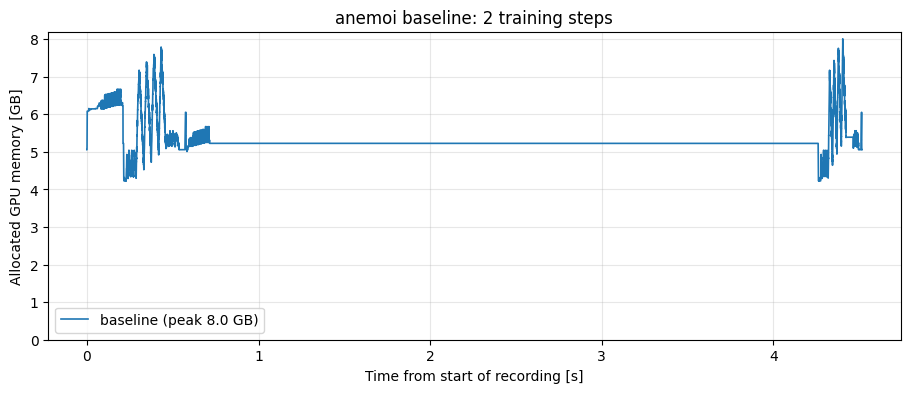

In [33]:
# REMOVE and replace with 
ph.plot_memory_timelines({"baseline": experiments["baseline"]}, title="anemoi baseline: 2 training steps")

**Exercise:** Download the file `memory_snapshot.pickle` from the baseline folder, and open it in
[https://pytorch.org/memory_viz](https://pytorch.org/memory_viz).

1. Find the two training steps.
2. Find the memory that stays the same for all the time (at the bottom). What is it?
3. Find the peak. Move the mouse over the largest blocks at the peak. Look at the stack trace.
   Which part of the model allocated them? Look for words such as `encoder`, `processor`, `decoder`, `mapper` or `loss`.

<details>
<summary>Answer to question 2</summary>

It is the **model state**: the weights, the gradients and the optimiser state.
The model has approximately 250 million parameters. Each parameter uses approximately 16 bytes
(4 for the weight, 4 for the gradient and 8 for the two Adam optimiser values). Thus the model state is approximately 4 GB.
This memory does not change when you change `num_chunks` or `gradient_checkpointing`.
</details>

add anotated screenshot as an answer

### 2.5 Look at the profiler trace of anemoi

The trace file is large (approximately 100 to 200 MB). It can take a minute to download it and to open it.

In [34]:
trace = ph.find_trace_file(experiments["baseline"])
print(f"Trace file: {trace}  ({trace.stat().st_size / 1e6:.0f} MB)")

Trace file: outputs/baseline/profiler/bb3cc54e-6e25-40b6-88bb-c81d17df4c01/ac6-305.bullx_3267928.None.1793092405474388984.pt.trace.json  (121 MB)


**Exercise:** Download the trace file and open it in [https://ui.perfetto.dev](https://ui.perfetto.dev).

1. Find the two `DistributedDataParallel.forward` blocks on the GPU row. Each block is one forward step.
2. Look at the GPU stream. Are there gaps, where the GPU does nothing?
3. Zoom in to the forward pass on the CPU row. Can you find the encoder, the 16 processor layers and the decoder?
   (Tip: Use the search box at the top. Search for `checkpoint` or `GraphTransformer`.)
4. Click on a kernel in the GPU stream. Perfetto shows its name and its duration.
   Use the arrow ("flow") to find the CPU operation that started it.

---
## Part 3: Experiments with gradient checkpointing and chunking

You now change one setting at a time, and you compare the peak memory and the throughput with the baseline.

> **Important:** Change **one** setting at a time. If you change two settings, you cannot know which setting caused the result.
>
> **Also important:** These runs are very short (20 steps). The throughput can change by 10 % to 15 % between two runs with the same settings.
> Do not trust a small difference in throughput. The peak memory is much more stable.

### 3.1 Gradient checkpointing

In anemoi, gradient checkpointing is **on** by default. You can set it for each part of the model:

```yaml
model:
  encoders:
    "0":
      mapper:
        gradient_checkpointing: False
  processor:
    gradient_checkpointing: False
  decoders:
    "0":
      mapper:
        gradient_checkpointing: False
```

**Make a prediction:** If you switch off gradient checkpointing, what happens to the memory? What happens to the speed?

Write your prediction here: ...

Now run the experiment.

In [35]:
NO_CKPT = [
    "model.encoders.0.mapper.gradient_checkpointing=False",
    "model.processor.gradient_checkpointing=False",
    "model.decoders.0.mapper.gradient_checkpointing=False",
]

experiments["no_checkpointing"] = ph.run_experiment("no_checkpointing", NO_CKPT)

Command: anemoi-training profile --config-name=perf_profiling system.output.root=outputs/no_checkpointing model.encoders.0.mapper.gradient_checkpointing=False model.processor.gradient_checkpointing=False model.decoders.0.mapper.gradient_checkpointing=False
Log file: outputs/no_checkpointing/run.log
Finished in 44 s with exit code 0.


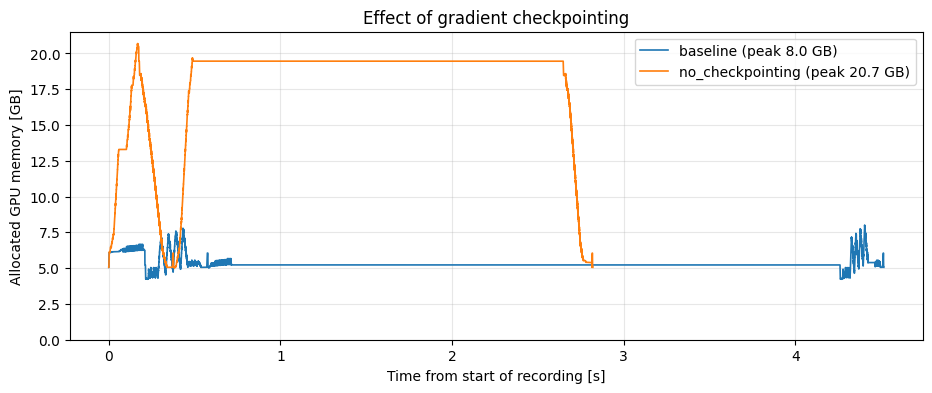

,peak memory [GB],throughput [it/s]
experiment,,
baseline,8.01,2.70
no_checkpointing,20.70,3.25


In [36]:
ph.plot_memory_timelines(
    {k: experiments[k] for k in ["baseline", "no_checkpointing"]},
    title="Effect of gradient checkpointing",
)
ph.summary_table({k: experiments[k] for k in ["baseline", "no_checkpointing"]})

**Questions:**

1. How much more memory does the model use without checkpointing?
2. How much faster is it?
3. In the plot, look at the shape of the curve. Without checkpointing, the memory increases during all of the forward pass. Why?

<details>
<summary>Answer</summary>

Without checkpointing, PyTorch keeps the activations of **all** the layers until the backward pass.
With checkpointing, it keeps only the input of each checkpointed part, and it calculates the activations again during the backward pass.

The model is faster without checkpointing, because it does not calculate the forward pass two times.

**Rule:** If the model fits in memory **without** checkpointing, switch checkpointing off. Then the training is faster.
You can also switch it off only in the processor, and keep it on in the mappers (where the activations are largest).
</details>

### 3.2 Chunking in the mappers

The setting `num_chunks` divides the edges of a mapper into parts. anemoi calculates one part after the other.
The default is 4 for the encoder and the decoder.

```yaml
model:
  encoders:
    "0":
      mapper:
        num_chunks: 4
  decoders:
    "0":
      mapper:
        num_chunks: 4
```

Remember Part 1: chunking helps most **together with** checkpointing.

We do two experiments, **with** checkpointing (the default): 1 chunk and 16 chunks.

**Make a prediction:** What happens to the memory and the speed with 1 chunk? With 16 chunks?

Write your prediction here: ...

In [ ]:
def mapper_chunks(n):
    return [f"model.encoders.0.mapper.num_chunks={n}", f"model.decoders.0.mapper.num_chunks={n}"]


experiments["chunks_1"] = ph.run_experiment("chunks_1", mapper_chunks(1))
experiments["chunks_16"] = ph.run_experiment("chunks_16", mapper_chunks(16))

In [ ]:
selection = ["chunks_1", "baseline", "chunks_16"]
ph.plot_memory_timelines({k: experiments[k] for k in selection}, title="Effect of mapper chunks (with checkpointing)")
ph.summary_table({k: experiments[k] for k in selection})

**Questions:**

1. Did the peak memory change much? Look at the plot. Where is the peak of the step?
2. Did the throughput change? Why?

<details>
<summary>Answer</summary>

At O96 resolution, the mappers are **not** the cause of the peak, because the grid is small.
Thus the number of chunks does not change the peak memory much.
But each chunk is a separate set of small GPU kernels, and small kernels use the GPU less well.
Thus more chunks make the model **slower**.

**Rule:** A setting that saves memory is only useful if it changes the part of the model that makes the peak.
Always look at the memory snapshot first. (In Part 4, experiment A, you can find the part that makes the peak at O96.)
</details>

### 3.3 Chunking at a higher resolution (N320)

Now we use the N320 grid (approximately 0.25°). It has 542 080 grid points. This is 13 times more than O96.
The mappers connect many more points and edges. Thus their activations are much larger.

The latent grid of the processor stays the same. Only the data grid changes.

**Make a prediction:** At N320, does the number of chunks change the peak memory?

> **Note:** With 1 chunk, the N320 run needs approximately 40 GB. If your GPU has less memory, the run stops with
> `CUDA out of memory`. This is also a good result. Then the helper function shows the error.
> The first N320 run also creates a new graph. This takes approximately 1 minute more.

In [ ]:
N320 = [
    f"system.input.dataset={N320_DATASET}",
    "system.input.graph=./graphs/n320_multiscale_graph.pt",
]

high_res = {}
for n in [1, 4, 16]:
    high_res[f"n320_chunks_{n}"] = ph.run_experiment(f"n320_chunks_{n}", N320 + mapper_chunks(n))

In [ ]:
ph.plot_memory_timelines(high_res, title="Effect of mapper chunks at N320 (with checkpointing)")
ph.summary_table(high_res)

**Questions:**

1. How much did the peak memory decrease from 1 chunk to 4 chunks? From 4 chunks to 16 chunks?
2. Look at the plot with 1 chunk. You can see four large peaks in each step. Which parts of the model make them?
3. What is the cost of more chunks?

<details>
<summary>Answer</summary>

1. On a GH200, we measured approximately 40 GB with 1 chunk, 15 GB with 4 chunks and 10 GB with 16 chunks.
   The saving becomes smaller for each additional chunk.
2. The four peaks are, in sequence: the encoder (forward), the decoder (forward), the decoder (backward) and the encoder (backward).
   With checkpointing, the forward pass of each mapper runs again in the backward pass.
3. The throughput decreases, mostly from 4 chunks to 16 chunks.

**Rule:** Use the lowest number of chunks that fits in memory. A good range is 4 to 16 for the mappers.
Always use a power of two (1, 2, 4, 8, 16, ...).
</details>

### 3.4 All the results

In [ ]:
results = ph.summary_table({**experiments, **high_res})
results

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, row in results.iterrows():
    ax.scatter(row["peak memory [GB]"], row["throughput [it/s]"], s=60)
    ax.annotate(name, (row["peak memory [GB]"], row["throughput [it/s]"]), textcoords="offset points", xytext=(6, 4))
ax.axvline(gpu.total_memory / 1e9, color="red", linestyle="--", label="GPU memory")
ax.set_xlabel("Peak memory [GB]  (lower is better)")
ax.set_ylabel("Throughput [it/s]  (higher is better)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("Memory and speed: you must find a balance")
plt.show()

**Discussion:** The best setting is at the **top left** of the plot. But there is always a trade-off:
less memory usually means less speed.

The correct procedure is:

1. Find a setting that **fits** in the GPU memory.
2. Then, use the remaining memory to make the model **faster** (fewer chunks, less checkpointing).

---
## Part 4: Your own experiments

Select one or more of the experiments below. Write your prediction before you run each experiment.

| Experiment | Overrides | Question |
|---|---|---|
| A. Processor chunks | `model.processor.num_chunks=1` or `=16` | Does the processor chunking change the memory or the speed? |
| B. Checkpointing in the processor only | `model.processor.gradient_checkpointing=False` | Is it a good compromise between memory and speed? |
| C. A wider model | `model.num_channels=2048` | How do the memory and the speed change when the model is wider? |
| D. Larger batch | `dataloader.batch_size.training=2` | Does the throughput (samples for each second) increase? |
| E. Make an OOM | `N320 + NO_CKPT + mapper_chunks(1)` | Does the run fit in memory? Read the error message. |

For experiment D: the snapshot steps must be a multiple of the batch size. Also add
`diagnostics.benchmark_profiler.snapshot.warmup=2` and `diagnostics.benchmark_profiler.snapshot.steps=2`.

In [ ]:
# Example: experiment A. Change the name and the overrides for your experiment.
experiments["processor_chunks_16"] = ph.run_experiment("processor_chunks_16", ["model.processor.num_chunks=16"])
ph.summary_table({k: experiments[k] for k in ["baseline", "processor_chunks_16"]})

In [ ]:
# Your experiment:

### 4.1 How to read a CUDA out-of-memory error

If a run uses too much memory, it stops with an error such as:

```
torch.OutOfMemoryError: CUDA out of memory. Tried to allocate 3.15 GiB. GPU 0 has a total capacity of 39.56 GiB
of which 6.80 GiB is free. Including non-PyTorch memory, this process has 36.61 GiB memory in use.
Of the allocated memory 31.66 GiB is allocated by PyTorch, and 4.11 GiB is reserved by PyTorch but unallocated.
If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
to avoid fragmentation.
```

Read it carefully:

* `Tried to allocate 3.15 GiB`: the size of the tensor that did not fit.
* `4.11 GiB is reserved by PyTorch but unallocated`: this memory is free, but it is in small pieces ("fragmentation").
  The 3.15 GiB tensor needs one continuous piece.
* The stack trace (above the error) tells you which part of the model was running. This tells you which `num_chunks` to change.

**First, always try this.** It decreases fragmentation. Put it in your SLURM script, before the training command:

```bash
export PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
```

### 4.2 Summary: what to do when your model does not fit

1. Set `PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True`.
2. Make sure that `gradient_checkpointing` is on.
3. Increase `num_chunks` in the part of the model that caused the error (the stack trace tells you).
4. If it still does not fit: shard the model over more GPUs (Part 5).

### 4.3 Summary: what to do when your model is too slow

1. Make sure that the data loader is fast enough (`avg_training_dataloader_throughput`).
   You can test this with `dataloader.fake_dataloading=True`.
2. If you have free memory: switch off `gradient_checkpointing` (first in the processor), and decrease `num_chunks`.
3. Use a fast attention backend (for example `triton` for the GraphTransformer).
4. Try `torch.compile` (the `model.compile` setting).
5. Look at the trace in Perfetto. Look for gaps on the GPU stream.

---
## Part 5: Thought experiment: model sharding

In this workshop, each person has one GPU. Thus you cannot test model sharding yourself.
But we can **estimate** what it does.

### 5.1 What is model sharding?

Usually, one copy of the model is on one GPU. With **model sharding**, one copy of the model uses **more than one GPU**.
In anemoi, you set it like this:

```yaml
system:
  hardware:
    num_gpus_per_model: 2
```

anemoi divides the **grid** into parts. Each GPU calculates the activations for its part of the grid only.

```
             1 GPU                                  2 GPUs (num_gpus_per_model: 2)
  ┌──────────────────────────┐          ┌─────────────────────┐   ┌─────────────────────┐
  │ model state (weights,    │          │ model state (copy)  │   │ model state (copy)  │
  │ gradients, optimiser)    │          ├─────────────────────┤   ├─────────────────────┤
  ├──────────────────────────┤          │ activations for     │   │ activations for     │
  │                          │          │ grid part 1         │◄─►│ grid part 2         │
  │ activations for          │          └─────────────────────┘   └─────────────────────┘
  │ the full grid            │                      ▲  communication  ▲
  │                          │                      └─────────────────┘
  └──────────────────────────┘
```

Important points:

* Each GPU has a **full copy** of the model state (weights, gradients, optimiser). Sharding does **not** make this part smaller.
* The **activations** are divided between the GPUs. This part becomes smaller.
* The GPUs must **communicate**, because a grid point needs information from its neighbours,
  and the attention heads in the processor need data from all the grid. Communication takes time.

### 5.2 Estimate the memory with sharding

We use a simple model of the memory:

$$ \text{peak memory} \approx \text{model state} + \frac{\text{activations}}{\text{number of GPUs}} $$

We use your baseline results. The model state is approximately 16 bytes for each parameter.

In [ ]:
N_PARAMS = 248e6  # number of parameters, from the anemoi log ("Total params")
model_state_gb = N_PARAMS * 16 / 1e9

for name in ["baseline", "no_checkpointing"]:
    peak = ph.peak_memory_gb(experiments[name])
    activations = peak - model_state_gb
    print(f"{name}:")
    for n_gpus in [1, 2, 4, 8]:
        estimate = model_state_gb + activations / n_gpus
        print(f"    {n_gpus} GPU(s): approximately {estimate:5.1f} GB for each GPU")

### 5.3 What if we use a higher resolution?

You measured the same model at two resolutions: O96 (baseline) and N320 (4 chunks). The settings are the same.

The activations have two parts:

* a part that does **not** change with the data grid (mostly the processor, on the latent grid)
* a part that increases with the number of grid points (mostly the mappers)

$$ \text{activations} \approx a + b \times \text{number of grid points} $$

With two measurements, we can calculate $a$ and $b$. Then we can estimate the memory for O1280 (approximately 9 km).

| Grid | Approximate resolution | Number of grid points |
|---|---|---|
| O96 | 1° | 40 320 |
| N320 | 0.25° | 542 080 |
| O1280 | 0.1° (9 km) | 6 599 680 |

In [ ]:
import numpy as np

grids = {"O96": 40_320, "N320": 542_080, "O1280": 6_599_680}

act_o96 = ph.peak_memory_gb(experiments["baseline"]) - model_state_gb
act_n320 = ph.peak_memory_gb(high_res["n320_chunks_4"]) - model_state_gb
b = (act_n320 - act_o96) / (grids["N320"] - grids["O96"])
a = act_o96 - b * grids["O96"]
print(f"Fixed part a = {a:.1f} GB, part for each grid point b = {b * 1e6:.1f} GB for each million points\n")

gpu_memory = gpu.total_memory / 1e9
print(f"Your GPU has {gpu_memory:.0f} GB.\n")
for grid, n_points in grids.items():
    activations = a + b * n_points
    line = []
    for n_gpus in [1, 2, 4, 8]:
        estimate = model_state_gb + activations / n_gpus
        fits = "fits" if estimate < 0.9 * gpu_memory else "OOM "
        line.append(f"{n_gpus} GPUs: {estimate:6.1f} GB ({fits})")
    print(f"{grid:6s} " + " | ".join(line))

> **Note:** This is a very simple estimate. In practice, the latent grid (processor) is also usually finer at higher resolution, and the model needs more memory.
> But the estimate shows the important idea: at high resolution, **one GPU is not sufficient**, even with checkpointing and chunking.

**Questions for discussion:**

1. At O1280, how many GPUs do you need for one copy of the model?
2. If you use 4 GPUs for each model, and you have 64 GPUs, how many copies of the model can you train at the same time (data parallel)?
   What happens to the batch size?
3. Sharding also divides the calculation between the GPUs. Do you think that 2 GPUs are 2 times faster than 1 GPU? Why not?
4. The GPUs in one node are connected with a fast connection (for example NVLink). The connection between nodes is slower.
   What happens if you shard one model over 2 nodes?

<details>
<summary>Answers</summary>

1. It is related to the memory of your GPU. With 96 GB, the estimate is 2 GPUs. With 40 GB, the estimate is 4 GPUs.
2. 64 / 4 = 16 copies. Each copy has a batch size of 1, so the total batch size is 16.
   If you use more GPUs for each model, you have fewer copies, and a smaller total batch.
3. No. The GPUs must communicate, and the communication takes time. Also, each GPU has less work, and small amounts of work use the GPU less well.
   The speedup is usually less than 2 times. With too many GPUs, the model can become slower.
4. The communication becomes much slower. Usually, it is better to keep one model in one node.
   Also, more GPUs for each model means a longer wait in the queue of a shared HPC system.
</details>

### 5.4 Future work

If you have access to a node with more than one GPU, try this:

```bash
anemoi-training profile --config-name=perf_profiling \
    system.hardware.num_gpus_per_node=2 \
    system.hardware.num_gpus_per_model=2
```

Then compare the memory snapshot and the trace with your 1-GPU results. In the trace, look for the communication kernels
(names with `nccl`, for example `ncclDevKernel_AllGather`). They show the time that the GPUs use to communicate.

---
## Summary

| Tool or setting | What it does | When to use it |
|---|---|---|
| Memory snapshot (`snapshot.enabled`) | Shows the GPU memory at each moment. Open it in [memory_viz](https://pytorch.org/memory_viz). | When you get an OOM error, or to find the part of the model that uses the most memory. |
| Profiler trace (`memory.enabled`) | Shows the operations on the CPU and the GPU at each moment. Open it in [Perfetto](https://ui.perfetto.dev). | When the model is slow, and you want to know why. |
| `gradient_checkpointing` | Calculates the activations again in the backward pass. Less memory, slower. | On, if the model does not fit. Off, if it fits without it. |
| `num_chunks` | Calculates the mappers in parts. Less memory with checkpointing, slower with many chunks. | Increase it when the mappers cause an OOM error. Use 4 to 16. |
| `PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` | Decreases memory fragmentation. | Always try it first. |
| `num_gpus_per_model` | Shards one model over more GPUs. | When the model does not fit on one GPU after all the other changes. |

### Further reading

* [anemoi performance optimisation guide](https://anemoi.readthedocs.io/projects/training/en/latest/user-guide/performance-optimisation.html)
* [anemoi benchmarking and profiler documentation](https://anemoi.readthedocs.io/projects/training/en/latest/user-guide/benchmarking.html)
* [PyTorch: understanding CUDA memory usage](https://pytorch.org/docs/stable/torch_cuda_memory.html)
* [A guide to the PyTorch CUDA caching allocator (blog)](https://zdevito.github.io/2022/08/04/cuda-caching-allocator.html)
* [Perfetto documentation](https://perfetto.dev/docs/)